# Proyecto BATSÚ — Notebook 05: Modelo de recompensa, entrenamiento del agente DQN y evaluación comparativa

**Universidad Cenfotec — MISIA** · Alvaro Granados, Jose Leonel Hernández

Este notebook cierra la fase de entrenamiento y calibración (Sección 3.4, fase 3) y la evaluación comparativa (fase 4). En orden:

1. Si el corpus ya tiene calificaciones del juez (notebook 04), entrena el **modelo de recompensa** que las generaliza (Sección 5.5): un regresor pequeño que predice `r_juez` a partir de (s, a, s'), para que el agente no invoque al LLM durante el entrenamiento. Si el corpus todavía no tiene juez, se entrena con la **recompensa proxy** (juez = 0), que es la primera iteración documentada en la decisión D6.
2. Entrena el agente **DQN** (Stable-Baselines3) sobre el ambiente del notebook 01, con el buffer de experiencia **precargado** con el corpus (Sección 3.5) y el criterio de parada por convergencia: se evalúa la política cada cierto número de pasos sobre un conjunto fijo de episodios y se detiene cuando deja de mejorar (Sección 3.5, criterio de parada).
3. Compara el agente contra los dos modelos de referencia de la Sección 3.4 (heurística estática y política aleatoria) con el mismo protocolo, y produce las curvas de la técnica 3.7.3 (recompensa acumulada, TD-Error) y la tabla comparativa del objetivo específico 6.

Corre en CPU. Con los parámetros por defecto tarda entre 5 y 15 minutos; `MAX_PASOS` acota la duración.

**Secciones**
1. Configuración
2. Parámetros
3. Corpus, manifiesto y ambiente
4. Modelo de recompensa (si hay juez)
5. Buffer precargado y agente DQN
6. Entrenamiento con criterio de parada
7. Evaluación comparativa y curvas
8. Guardado de resultados


## 1. Configuración

CPU basta. Se instala `stable-baselines3`, que trae la implementación de referencia de DQN (Raffin et al., 2021; Tabla 5.2).


In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import sys, json, time
from datetime import datetime, timezone
import jupyter_client.session as _jcs
_jcs.utcnow = lambda: datetime.now(timezone.utc)   # sustituye la función obsoleta del propio Jupyter que genera el aviso de utcnow(); no interviene en los cálculos
import numpy as np
import pandas as pd

NOMBRE_CARPETA = 'DatosBatsuv2'
candidatos = [p for p in Path('/content/drive/MyDrive').rglob(NOMBRE_CARPETA) if p.is_dir()]
assert candidatos, f'No se encontró la carpeta "{NOMBRE_CARPETA}"'
BASE_DIR = candidatos[0]
CORPUS_DIR = BASE_DIR / 'corpus'
RESULTADOS_DIR = BASE_DIR / 'resultados'
RESULTADOS_DIR.mkdir(exist_ok=True)
sys.path.insert(0, str(BASE_DIR))

!pip install -q gymnasium stable-baselines3 pyarrow 2>&1 | tail -1
import torch, gymnasium as gym, stable_baselines3 as sb3
import matplotlib.pyplot as plt
print('torch', torch.__version__, '· SB3', sb3.__version__, '· gymnasium', gym.__version__)


Mounted at /content/drive
torch 2.11.0+cpu · SB3 2.9.2 · gymnasium 1.4.0


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


**Nota sobre las advertencias de esta celda.** Al instalar las librerías aparecen dos avisos que no afectan los resultados:

“Gym has been unmaintained since 2022…”: lo emite Stable-Baselines3 al detectar el paquete antiguo gym preinstalado en Colab. Este notebook no lo usa; el ambiente se construye con gymnasium, su reemplazo mantenido, cuya versión se imprime al final de la celda.
“datetime.utcnow() is deprecated…”: proviene del propio Jupyter al fechar los mensajes de salida; no interviene en ningún cálculo.

No se actualizan paquetes para no alterar las versiones registradas en el manifiesto de resultados (torch, SB3, gymnasium), que son las que respaldan la reproducibilidad.

## 2. Parámetros

- **`ETIQUETA_CORPUS`**: corpus con el que se precarga el buffer. Los parámetros del simulador (escala de cierre, prior) se leen de su manifiesto, para que el ambiente de entrenamiento sea exactamente el que generó el corpus.
- **`USAR_JUEZ`**: `'auto'` usa el modelo de recompensa si el corpus tiene juez, y la recompensa proxy si no; `'proxy'` fuerza juez = 0 (útil para comparar las dos iteraciones de D6).
- **Hiperparámetros del DQN**: red de dos capas de 64, γ = 0.95, exploración ε-greedy que decae de 1.0 a 0.05 en el 30 % del entrenamiento, red objetivo actualizada cada 1 000 pasos. `learning_starts = 0` porque el buffer ya viene precargado.
- **Criterio de parada**: se evalúa cada `EVAL_CADA` pasos sobre `N_EVAL_EPISODIOS` episodios fijos (los mismos para todas las políticas); se detiene tras `PACIENCIA` evaluaciones sin mejorar el retorno medio, o al llegar a `MAX_PASOS`.
- **`SEMILLA`**: fija torch, numpy y el ambiente para reproducibilidad.


In [2]:
ETIQUETA_CORPUS = 'v0_escala05_prior40'
USAR_JUEZ = 'auto'            # 'auto' | 'proxy'
CLAVE_ALEATORIA = 20260925     # clave de reproducibilidad (random seed); no confundir con las 60 semillas de turista

# DQN (Stable-Baselines3)
HIPER = dict(learning_rate=5e-4, buffer_size=300_000, learning_starts=0, batch_size=128, gamma=0.95,
             train_freq=4, gradient_steps=1, target_update_interval=1_000,
             exploration_fraction=0.30, exploration_initial_eps=1.0, exploration_final_eps=0.05,
             policy_kwargs=dict(net_arch=[64, 64]))

# Criterio de parada y protocolo de evaluación (Sección 3.5)
MAX_PASOS = 200_000
EVAL_CADA = 10_000
N_SEL_EPISODIOS = 300         # conjunto de selección: decide la parada y el mejor modelo (60 semillas × 5)
N_TEST_EPISODIOS = 600        # conjunto de prueba independiente: solo para la tabla final (60 semillas × 10)
PACIENCIA = 5
CLAVES_REPLICAS = [CLAVE_ALEATORIA + i for i in range(5)]   # 5 réplicas independientes de entrenamiento del DQN

RUTA_CORPUS = CORPUS_DIR / f'corpus_{ETIQUETA_CORPUS}.parquet'
RUTA_MANIF = CORPUS_DIR / f'manifiesto_{ETIQUETA_CORPUS}.json'
assert RUTA_CORPUS.exists() and RUTA_MANIF.exists(), 'Falta el corpus o su manifiesto (notebook 02)'
print('Corpus:', RUTA_CORPUS.name)


Corpus: corpus_v0_escala05_prior40.parquet


## 3. Corpus, manifiesto y ambiente

Se carga el corpus y su manifiesto, se aplican al simulador los parámetros con los que se generó (escala de cierre y prior), y se determina si hay juez. Se construye el ambiente de entrenamiento y el conjunto fijo de episodios de evaluación: cada política se evaluará con las mismas 300 combinaciones (semilla, generador aleatorio), de modo que las diferencias entre políticas no se deban al azar del turista simulado.


In [3]:
import batsu_sim as bs
corpus = pd.read_parquet(RUTA_CORPUS)
manif = json.load(open(RUTA_MANIF, encoding='utf-8'))
bs.ESCALA_P_CIERRE = manif['parametros']['escala_p_cierre']
bs.PRIOR_PUNTOS = manif['parametros']['prior_puntos']

hay_juez = manif.get('juez', {}).get('completado', False) or ('r_juez' in corpus and (corpus['r_juez'] != 0).any())
modo_juez = 'modelo' if (USAR_JUEZ == 'auto' and hay_juez) else 'proxy'
COLS_S = [c for c in corpus.columns if c.startswith('s_')]
COLS_SP = [c for c in corpus.columns if c.startswith('sp_')]
n_ep = corpus.groupby(['id_semilla', 'corrida']).ngroups
print(f'Corpus: {len(corpus):,} transiciones · {n_ep:,} episodios · escala {bs.ESCALA_P_CIERRE} · prior {bs.PRIOR_PUNTOS} · '
      f'juez en corpus: {"sí" if hay_juez else "no"} → modo de recompensa: {modo_juez}')

# Conjuntos fijos de evaluación: (id_semilla, semilla_rng). Selección y prueba salen de generadores distintos
# y no comparten ninguna semilla aleatoria del turista simulado.
ids = list(bs.semillas['id'])
rng_sel = np.random.default_rng(CLAVE_ALEATORIA + 1)
SEL_SET = [(ids[i % 60], int(rng_sel.integers(1e9))) for i in range(N_SEL_EPISODIOS)]
rng_test = np.random.default_rng(CLAVE_ALEATORIA + 2)
TEST_SET = [(ids[i % 60], int(rng_test.integers(1e9))) for i in range(N_TEST_EPISODIOS)]
assert not set(SEL_SET) & set(TEST_SET), 'selección y prueba comparten episodios'
print(f'Conjunto de selección: {len(SEL_SET)} episodios · conjunto de prueba: {len(TEST_SET)} episodios · sin solapamiento')

def evaluar(politica, env, conjunto, mascara=False):
    """Evalúa una política (función env -> acción) sobre un conjunto fijo. Devuelve métricas del objetivo 6
    y la lista de retornos por episodio (clave '_retornos') para los intervalos de confianza."""
    rets, longs, des, viol = [], [], [], 0
    for sid, seed in conjunto:
        obs, _ = env.reset(seed=seed, options={'id': sid})
        ret = 0.0
        while True:
            a = politica(env.unwrapped, obs)
            if mascara:
                m = env.unwrapped.mascara_acciones()
                if not m[a]:
                    a = 0 if m[0] else int(np.flatnonzero(m)[0])
            obs, r, term, trunc, info = env.step(a)
            ret += r; viol += int(info['violacion_trust_gate'])
            if term or trunc:
                break
        rets.append(ret); longs.append(info['turno']); des.append(info['desenlace'])
    d = pd.Series(des).value_counts(normalize=True)
    return {'retorno': float(np.mean(rets)), 'turnos': float(np.mean(longs)), 'conversion': float(d.get('conversion', 0)),
            'inviable': float(d.get('recomendacion_inviable', 0)), 'negativos': float(d.get('rechazo', 0) + d.get('abandono', 0) + d.get('recomendacion_inviable', 0)),
            'violaciones_por_ep': viol / len(conjunto), '_retornos': rets}


Parámetros cargados. Acciones: 7 | Estados afectivos: 5
Semillas: 60 OK · distancia máxima 267.1 km · inviables: ['CR-TUR-005', 'CR-TUR-020', 'CR-TUR-035', 'CR-TUR-044', 'CR-TUR-054']
Tabla de reacción: 35 celdas OK
Modificadores: 7 OK
Dinámica OK. Desenlaces al cerrar (entusiasmado, oferta baja, prior=conversión):
{'conversion': 0.82, 'avance_parcial': 0.144, 'abandono': 0.036} | esperado: conv (75+40)/140=0.82, avance 0.14, abandono 0.04
Ambiente creado · Box(0.0, 1.0, (21,), float32) · Discrete(7)
Máscara Trust Gate para CR-TUR-001 (presupuesto bajo, solo texto): {'solicitar_informacion': True, 'ofrecer_paquete_bajo': True, 'ofrecer_paquete_medio': False, 'ofrecer_paquete_alto': False, 'enviar_activo': False, 'escalar_humano': True, 'cerrar_conversacion': True}
Corpus: 26,343 transiciones · 6,000 episodios · escala 0.5 · prior 40 · juez en corpus: sí → modo de recompensa: modelo
Conjunto de selección: 300 episodios · conjunto de prueba: 600 episodios · sin solapamiento


## 4. Modelo de recompensa (si hay juez)

Cuando el corpus tiene `r_juez`, se entrena un regresor que lo predice a partir de la transición: el vector de estado s (20), la acción en one-hot (7) y el vector s' (20), 47 entradas en total. Es una red de dos capas de 64 unidades entrenada con error cuadrático, con partición de validación **por episodio** (no por turno), para que la métrica no esté inflada por turnos vecinos del mismo diálogo. Se reporta el error absoluto medio y el R² en validación, que es la calidad del modelo de recompensa que la Sección 5.5 exige reportar junto con los resultados de convergencia.

El modelo se usa después dentro de un *wrapper* del ambiente que suma `r_juez` predicho a la recompensa de cada paso. Si el corpus no tiene juez, esta sección se salta y `r_juez = 0`.


In [4]:
import shutil
ruta_rm = RESULTADOS_DIR / f'modelo_recompensa_{ETIQUETA_CORPUS}.pt'
respaldo_rm = RESULTADOS_DIR / f'modelo_recompensa_{ETIQUETA_CORPUS}_corrida_definitiva.pt'
if not respaldo_rm.exists():
    shutil.copy(ruta_rm, respaldo_rm)
print('Respaldo del modelo de recompensa:', respaldo_rm.name)

Respaldo del modelo de recompensa: modelo_recompensa_v0_escala05_prior40_corrida_definitiva.pt


In [5]:
import torch.nn as nn

modelo_recompensa = None
if modo_juez == 'modelo':
    torch.manual_seed(CLAVE_ALEATORIA)
    ruta_juez = CORPUS_DIR / f'juez_{ETIQUETA_CORPUS}.jsonl'
    ids_juzgados = {json.loads(l)['id_transicion'] for l in open(ruta_juez, encoding='utf-8') if json.loads(l).get('valido')} if ruta_juez.exists() else set(corpus.loc[corpus['r_juez'] != 0, 'id_transicion'])
    juzg = corpus[corpus['id_transicion'].isin(ids_juzgados)].copy()
    A = np.eye(len(bs.ACCIONES), dtype=np.float32)[juzg['accion'].values]
    X = np.hstack([juzg[COLS_S].values.astype(np.float32), A, juzg[COLS_SP].values.astype(np.float32)])
    y = juzg['r_juez'].values.astype(np.float32)
    ep_id = (juzg['id_semilla'] + '-' + juzg['corrida'].astype(str)).values
    eps_unicos = np.unique(ep_id); rng = np.random.default_rng(CLAVE_ALEATORIA)
    val_eps = set(rng.choice(eps_unicos, size=int(0.2 * len(eps_unicos)), replace=False))
    mval = np.array([e in val_eps for e in ep_id])
    Xt, yt, Xv, yv = map(torch.tensor, (X[~mval], y[~mval], X[mval], y[mval]))

    modelo_recompensa = nn.Sequential(nn.Linear(X.shape[1], 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1))
    opt = torch.optim.Adam(modelo_recompensa.parameters(), lr=1e-3)
    for epoca in range(200):
        perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), 256):
            idx = perm[i:i+256]
            loss = nn.functional.mse_loss(modelo_recompensa(Xt[idx]).squeeze(1), yt[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    modelo_recompensa.eval()
    with torch.no_grad():
        pv = modelo_recompensa(Xv).squeeze(1).numpy()
    mae = float(np.mean(np.abs(pv - yv.numpy()))); r2 = 1 - float(np.sum((pv - yv.numpy())**2) / np.sum((yv.numpy() - yv.numpy().mean())**2))
    print(f'Modelo de recompensa: {len(Xt):,} transiciones de entrenamiento · {len(Xv):,} de validación ({len(val_eps)} episodios)')
    mse = float(np.mean((pv - yv.numpy())**2))
    print(f'Validación: MSE = {mse:.4f} · MAE = {mae:.3f} (escala de r_juez en [-1, 1]) · R² = {r2:.3f} · entradas: {X.shape[1]}')
    torch.save(modelo_recompensa.state_dict(), RESULTADOS_DIR / f'modelo_recompensa_{ETIQUETA_CORPUS}.pt')
else:
    print('Sin juez en el corpus: se entrena con recompensa proxy (r_juez = 0), primera iteración de D6')


Modelo de recompensa: 21,181 transiciones de entrenamiento · 5,162 de validación (1200 episodios)
Validación: MSE = 0.0711 · MAE = 0.198 (escala de r_juez en [-1, 1]) · R² = 0.184 · entradas: 49


In [6]:
# Condición de uso del modelo de recompensa (Sección 5.5): preservar el orden de preferencia del juez entre acciones
from scipy.stats import spearmanr
with torch.no_grad():
    pred_v = modelo_recompensa(Xv).squeeze(1).numpy()
val = juzg[mval].assign(pred=pred_v, real=yv.numpy())
por_accion = val.groupby('accion_nombre')[['real', 'pred']].mean().sort_values('real', ascending=False)
por_estado = val.groupby('estado_antes')[['real', 'pred']].mean().sort_values('real', ascending=False)
rho_a, _ = spearmanr(por_accion['real'], por_accion['pred'])
rho_e, _ = spearmanr(por_estado['real'], por_estado['pred'])
print('Media de r_juez real vs predicho por acción (validación):')
print(por_accion.round(3).to_string())
print(f'\nSpearman del orden entre acciones: ρ = {rho_a:.3f}')
print('\nPor estado afectivo previo:')
print(por_estado.round(3).to_string())
print(f'\nSpearman del orden entre estados: ρ = {rho_e:.3f}')

Media de r_juez real vs predicho por acción (validación):
                        real   pred
accion_nombre                      
ofrecer_paquete_medio  0.310  0.318
ofrecer_paquete_alto   0.296  0.300
ofrecer_paquete_bajo   0.286  0.291
solicitar_informacion  0.266  0.262
enviar_activo          0.174  0.175
cerrar_conversacion    0.104  0.052
escalar_humano         0.000 -0.037

Spearman del orden entre acciones: ρ = 1.000

Por estado afectivo previo:
               real   pred
estado_antes              
entusiasmado  0.333  0.332
ansioso       0.239  0.223
frustrado     0.164  0.168
indeciso      0.150  0.160
desconfiado   0.141  0.124

Spearman del orden entre estados: ρ = 1.000


In [7]:
import hashlib
modelo_recompensa.load_state_dict(torch.load(respaldo_rm)); modelo_recompensa.eval()
shutil.copy(respaldo_rm, ruta_rm)
print('Huella del modelo de recompensa:', hashlib.sha256(open(ruta_rm, 'rb').read()).hexdigest()[:16], '(debe ser f804e565bb36d5ba)')

Huella del modelo de recompensa: f804e565bb36d5ba (debe ser f804e565bb36d5ba)


## 5. Buffer precargado y agente DQN

Se crea el ambiente de entrenamiento (con el wrapper del modelo de recompensa si aplica), se instancia el DQN de Stable-Baselines3 con los hiperparámetros de la Sección 2 y se **precarga su buffer de experiencia** con todas las transiciones del corpus: (s, a, r, s', terminated), con la marca de truncación en `infos` para que SB3 haga *bootstrap* del valor futuro en los episodios truncados y no en los terminados (Tabla 5.11). Así el agente empieza a aprender desde el primer paso sobre la experiencia de la política heurística (Sección 3.5), y la interacción posterior con el simulador va añadiendo su propia experiencia.

La recompensa que se carga en el buffer es la del corpus en el modo elegido: con `r_juez` del juez real si hay, o con `r_juez = 0` en modo proxy.


In [8]:
from stable_baselines3 import DQN
from stable_baselines3.common.monitor import Monitor

class EnvConRecompensaModelo(gym.Wrapper):
    """Suma al reward la predicción del modelo de recompensa (sustituto del juez, Sección 5.5)."""
    def __init__(self, env, modelo):
        super().__init__(env); self.modelo = modelo; self._obs = None
    def reset(self, **kw):
        self._obs, info = self.env.reset(**kw); return self._obs, info
    def step(self, a):
        obs2, r, term, trunc, info = self.env.step(a)
        if self.modelo is not None:
            x = np.concatenate([self._obs, np.eye(len(bs.ACCIONES), dtype=np.float32)[int(a)], obs2]).astype(np.float32)
            with torch.no_grad():
                rj = float(self.modelo(torch.tensor(x)[None]).item())
            r += rj; info['r_juez'] = rj
        self._obs = obs2
        return obs2, r, term, trunc, info

def hacer_env():
    e = bs.BatsuEnv(bs.semillas)
    return EnvConRecompensaModelo(e, modelo_recompensa) if modo_juez == 'modelo' else e

env_eval = hacer_env()

# Transiciones del corpus que se precargan en el buffer (Sección 3.5), con la recompensa del modo elegido
r_col = corpus['reward'] if modo_juez == 'modelo' else (corpus['r_shaping'] + corpus['r_trust'] + corpus['r_terminal'])
S, SP = corpus[COLS_S].values.astype(np.float32), corpus[COLS_SP].values.astype(np.float32)
A_CORPUS, R_CORPUS = corpus['accion'].values, r_col.values.astype(np.float32)
TERM, TRUNC = corpus['terminated'].values.astype(bool), corpus['truncated'].values.astype(bool)

def crear_agente(clave):
    """DQN nuevo con la clave aleatoria dada y el buffer de experiencia precargado con todo el corpus."""
    torch.manual_seed(clave); np.random.seed(clave)
    env_train = Monitor(hacer_env())
    agente = DQN('MlpPolicy', env_train, seed=clave, verbose=0, **HIPER)
    for i in range(len(corpus)):
        agente.replay_buffer.add(S[i:i+1], SP[i:i+1], np.array([A_CORPUS[i]]), np.array([R_CORPUS[i]], dtype=np.float32),
                                 np.array([TERM[i]]), [{'TimeLimit.truncated': bool(TRUNC[i])}])
    return agente, env_train

_a, _ = crear_agente(CLAVE_ALEATORIA)
print(f'Buffer precargado con {_a.replay_buffer.size():,} transiciones · modo de recompensa: {modo_juez} · '
      f'réplicas de entrenamiento (claves aleatorias): {CLAVES_REPLICAS}')
del _a

Buffer precargado con 26,343 transiciones · modo de recompensa: modelo · réplicas de entrenamiento (claves aleatorias): [20260925, 20260926, 20260927, 20260928, 20260929]


## 6. Entrenamiento con criterio de parada

El agente entrena en una sola llamada de hasta `MAX_PASOS` pasos (así la exploración ε decae sobre el horizonte completo), con un *callback* que cada `EVAL_CADA` pasos evalúa la política determinista (sin exploración) sobre el conjunto fijo de evaluación y se registran: retorno medio, tasa de conversión, tasa de recomendaciones inviables, y la pérdida de entrenamiento (el TD-Error medio del bloque, técnica 3.7.3). Si el retorno medio no mejora en `PACIENCIA` evaluaciones consecutivas, se detiene y se restaura el mejor modelo. Cada evaluación se imprime para seguir la convergencia.


In [9]:
from stable_baselines3.common.callbacks import BaseCallback

class ParadaPorConvergencia(BaseCallback):
    """Evalúa cada EVAL_CADA pasos sobre el conjunto de SELECCIÓN; guarda el mejor modelo; detiene tras PACIENCIA sin mejora."""
    def __init__(self, ruta_modelo):
        super().__init__(); self.ruta = ruta_modelo; self.historial = []
        self.mejor = -np.inf; self.sin_mejora = 0; self.mejor_paso = 0; self.t0 = time.time()
    def _on_step(self):
        if self.num_timesteps % EVAL_CADA != 0:
            return True
        pol = lambda env, obs: int(self.model.predict(obs, deterministic=True)[0])
        m = evaluar(pol, env_eval, SEL_SET); m.pop('_retornos')
        m.update(paso=self.num_timesteps, td_loss=float(self.model.logger.name_to_value.get('train/loss', np.nan)),
                 eps=float(self.model.exploration_rate), minutos=(time.time() - self.t0) / 60)
        self.historial.append(m)
        mejora = m['retorno'] > self.mejor + 1e-6
        print(f"  paso {m['paso']:>7,} · retorno {m['retorno']:6.2f} · conv {m['conversion']:.2f} · inviable {m['inviable']:.2f} · "
              f"viol/ep {m['violaciones_por_ep']:.2f} · TD-loss {m['td_loss']:.3f} · ε {m['eps']:.2f}{'  ← mejor' if mejora else ''}")
        if mejora:
            self.mejor, self.sin_mejora, self.mejor_paso = m['retorno'], 0, m['paso']
            self.model.save(self.ruta)
        else:
            self.sin_mejora += 1
            if self.sin_mejora >= PACIENCIA:
                print(f'  Criterio de parada: {PACIENCIA} evaluaciones sin mejora. Mejor retorno {self.mejor:.2f} en el paso {self.mejor_paso:,}.')
                return False
        return True

#replicas = {}      # clave aleatoria -> resumen del entrenamiento de esa réplica
#agentes = {}       # clave aleatoria -> mejor modelo de esa réplica
#t_total = time.time()
#for i, clave in enumerate(CLAVES_REPLICAS, 1):
#    print(f'\n=== Réplica {i}/{len(CLAVES_REPLICAS)} (clave aleatoria {clave}) ===')
#    ruta = RESULTADOS_DIR / f'dqn_{ETIQUETA_CORPUS}_{modo_juez}_r{i}'
#    agente, env_train = crear_agente(clave)
#    cb = ParadaPorConvergencia(ruta)
#    agente.learn(total_timesteps=MAX_PASOS, callback=cb, log_interval=None)
#    replicas[clave] = {'replica': i, 'hist': pd.DataFrame(cb.historial), 'pasos': int(agente.num_timesteps),
#                       'mejor_paso': int(cb.mejor_paso), 'mejor_sel': float(cb.mejor), 'ruta': ruta.name,
#                       'minutos': (time.time() - cb.t0) / 60}
#    agentes[clave] = DQN.load(ruta, env=env_train)
#    print(f'  Entrenamiento: {agente.num_timesteps:,} pasos · {replicas[clave]["minutos"]:.1f} min · '
#          f'mejor modelo del paso {cb.mejor_paso:,} (retorno en selección {cb.mejor:.2f})')

#print(f'\n{len(replicas)} réplicas en {(time.time()-t_total)/60:.1f} min · mejor paso por réplica: {[r["mejor_paso"] for r in replicas.values()]}')

# Carga de la corrida guardada (sin reentrenar): modelos, historial y registro de la sección 8
replicas, agentes = {}, {}
sufijo = f'{ETIQUETA_CORPUS}_{modo_juez}'
registro_previo = json.load(open(RESULTADOS_DIR / f'registro_{sufijo}.json', encoding='utf-8'))
hist_previo = pd.read_csv(RESULTADOS_DIR / f'entrenamiento_{sufijo}.csv')
for i_str, r in registro_previo['replicas'].items():
    i, clave = int(i_str), r['clave']
    h = hist_previo[hist_previo['replica'] == i].drop(columns=['replica']).reset_index(drop=True)
    replicas[clave] = {'replica': i, 'hist': h, 'pasos': r['pasos'], 'mejor_paso': r['mejor_paso'],
                       'mejor_sel': r['retorno_seleccion'], 'ruta': r['modelo'], 'minutos': r['minutos']}
    agentes[clave] = DQN.load(RESULTADOS_DIR / r['modelo'], env=Monitor(hacer_env()))
print(f"{len(replicas)} réplicas cargadas · entrenadas el {registro_previo['fecha']}")


5 réplicas cargadas · entrenadas el 2026-10-14 17:46:28


## 7. Evaluación comparativa y curvas

Se evalúan con el mismo protocolo (mismos 300 episodios) las cuatro políticas del objetivo específico 6:

- **Aleatoria**: piso de desempeño.
- **Heurística estática** (ε = 0): el modelo de referencia (Sección 3.4).
- **DQN**: el agente entrenado, decisiones sin filtro.
- **DQN + Trust Gate**: el agente con la máscara de acciones aplicada en inferencia (Capa de Seguridad L3, Sección 2.2): las acciones prohibidas se sustituyen por "solicitar información". Es la configuración de despliegue.

Se grafican la curva de aprendizaje (retorno de evaluación por paso), la pérdida TD y la distribución de desenlaces de cada política.


Evaluación sobre el conjunto de prueba (600 episodios). IC95 del retorno: sobre episodios para las referencias, sobre las 5 réplicas para el DQN.

                         retorno  retorno_ic95  turnos  conversion  inviable  negativos  violaciones_por_ep
Aleatoria                  0.089         0.513   3.248       0.220     0.052      0.517               0.515
Heurística (referencia)    7.532         0.519   4.328       0.585     0.065      0.142               0.080
DQN                        8.488         0.055   4.683       0.609     0.000      0.099               0.000
DQN + Trust Gate           8.488         0.055   4.683       0.609     0.000      0.099               0.000

DQN por réplica (prueba):
 replica  retorno  conversion  inviable  violaciones_por_ep
       1    8.461       0.610       0.0                 0.0
       2    8.480       0.610       0.0                 0.0
       3    8.461       0.598       0.0                 0.0
       4    8.474       0.610       0.0       

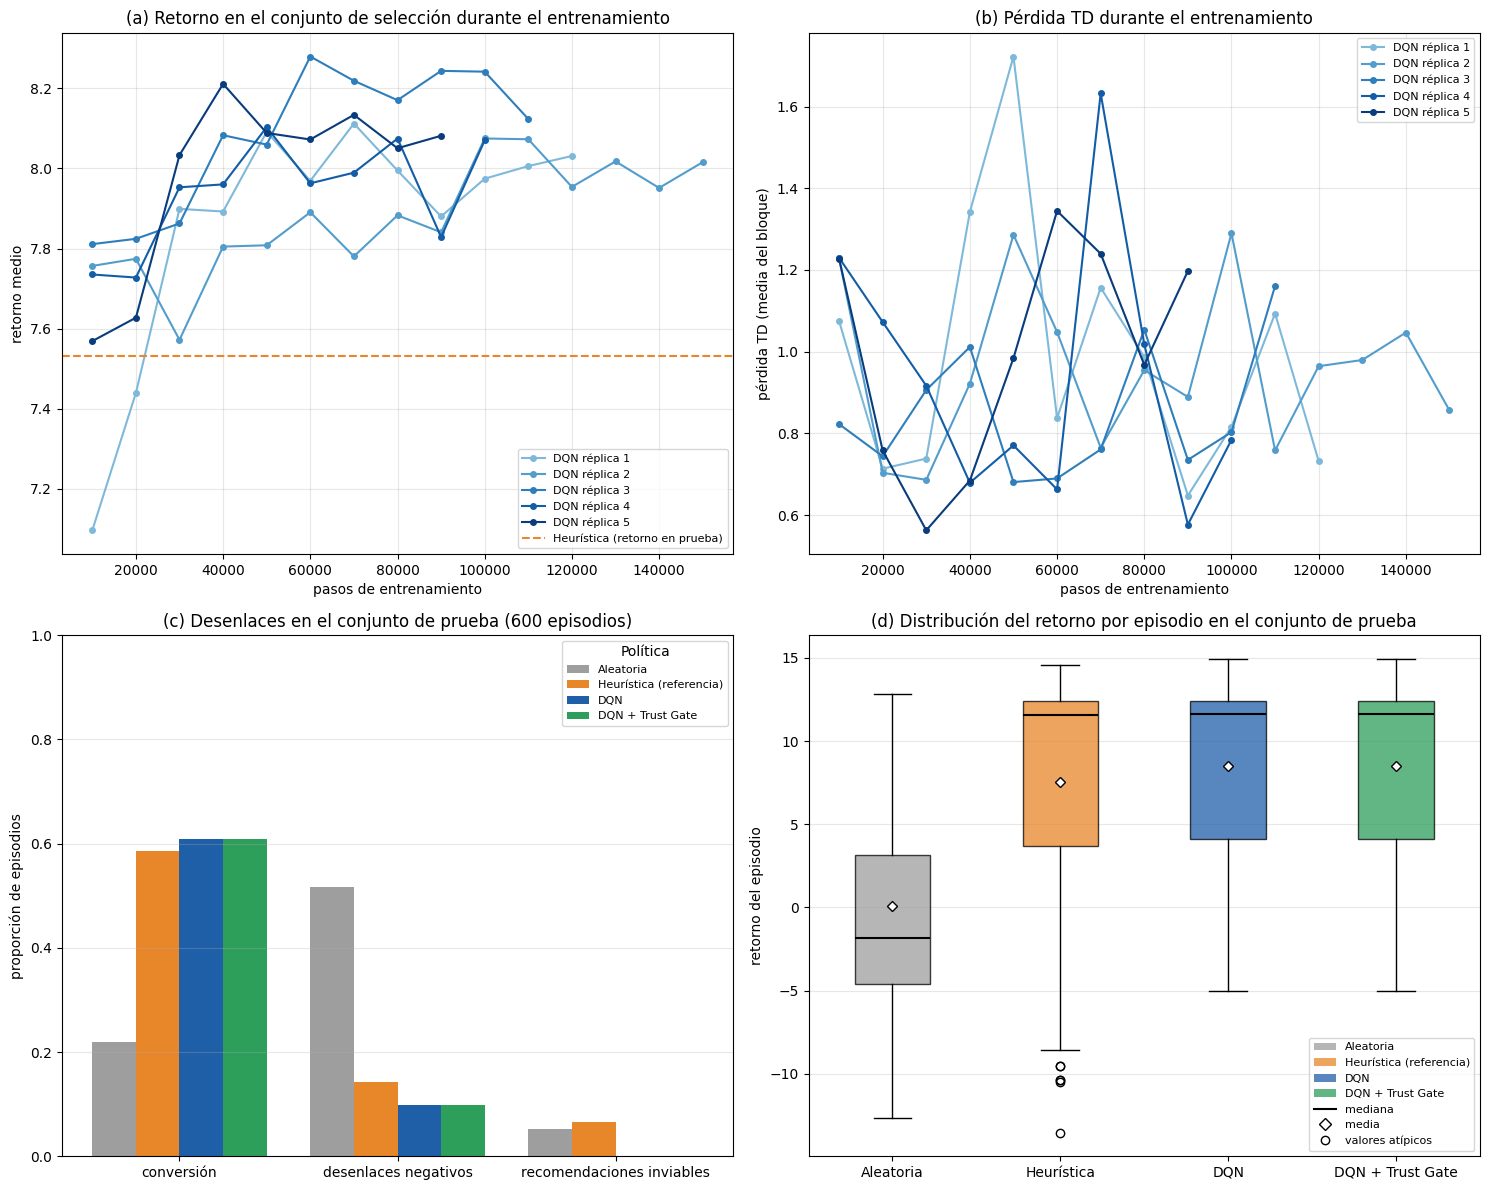

Figuras guardadas en resultados


In [10]:
from scipy.stats import t as t_student

pol_heur = lambda env, obs: bs.politica_heuristica(env, 0.0)
pol_rand = lambda env, obs: bs.politica_aleatoria(env)
METRICAS = ['retorno', 'turnos', 'conversion', 'inviable', 'negativos', 'violaciones_por_ep']

def ic95(x):
    """Media y semiamplitud del intervalo de confianza del 95 % (t de Student)."""
    x = np.asarray(x, dtype=float); n = len(x)
    return float(x.mean()), (float(t_student.ppf(0.975, n - 1) * x.std(ddof=1) / np.sqrt(n)) if n > 1 else 0.0)

# 1) Políticas de referencia sobre el conjunto de PRUEBA: IC sobre los episodios
filas, ic, retornos = {}, {}, {}
for nombre, pol in [('Aleatoria', pol_rand), ('Heurística (referencia)', pol_heur)]:
    m = evaluar(pol, env_eval, TEST_SET); rets = m.pop('_retornos')
    filas[nombre] = m; ic[nombre] = ic95(rets)[1]; retornos[nombre] = rets

# 2) DQN: cada réplica sobre el conjunto de PRUEBA; se reporta la media entre réplicas ± IC95 (t de Student, n = réplicas)
por_replica = []
for clave, ag in agentes.items():
    pol = lambda env, obs, ag=ag: int(ag.predict(obs, deterministic=True)[0])
    for nombre, masc in [('DQN', False), ('DQN + Trust Gate', True)]:
        m = evaluar(pol, env_eval, TEST_SET, mascara=masc); rets = m.pop('_retornos')
        retornos.setdefault(nombre, []).extend(rets)       # todas las réplicas juntas: réplicas × 600 episodios
        por_replica.append({'politica': nombre, 'replica': replicas[clave]['replica'], 'clave': clave, **m})
por_replica = pd.DataFrame(por_replica)
for nombre in ['DQN', 'DQN + Trust Gate']:
    sub = por_replica[por_replica['politica'] == nombre]
    filas[nombre] = sub[METRICAS].mean().to_dict(); ic[nombre] = ic95(sub['retorno'])[1]

comparacion = pd.DataFrame(filas).T[METRICAS].round(3)
comparacion.insert(1, 'retorno_ic95', pd.Series(ic).round(3))
print(f'Evaluación sobre el conjunto de prueba ({len(TEST_SET)} episodios). IC95 del retorno: sobre episodios '
      f'para las referencias, sobre las {len(agentes)} réplicas para el DQN.\n')
print(comparacion.to_string())
print('\nDQN por réplica (prueba):')
print(por_replica[por_replica['politica'] == 'DQN'][['replica', 'retorno', 'conversion', 'inviable', 'violaciones_por_ep']]
      .round(3).to_string(index=False))

# Control de sobreajuste al conjunto de selección: retorno en selección vs en prueba, por réplica
sel = pd.Series({replicas[c]['replica']: replicas[c]['mejor_sel'] for c in agentes})
prueba = por_replica[por_replica['politica'] == 'DQN'].set_index('replica')['retorno']
print('\nRetorno DQN selección / prueba por réplica: ' + ' · '.join(f'r{i}: {sel[i]:.2f} / {prueba[i]:.2f}' for i in sel.index))

# Figuras (un color por política; cada panel se explica por sí solo y se guarda también por separado)
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
COLOR = {'Aleatoria': '#9e9e9e', 'Heurística (referencia)': '#e8862a', 'DQN': '#1f5fa8', 'DQN + Trust Gate': '#2e9e5b'}
azules = plt.cm.Blues(np.linspace(0.45, 0.95, len(replicas)))     # tonos de azul para las réplicas del DQN
hist = pd.concat([r['hist'].assign(replica=r['replica']) for r in replicas.values()], ignore_index=True)
politicas = list(comparacion.index)

def panel_a(ax):
    for (i, g), c in zip(hist.groupby('replica'), azules):
        ax.plot(g['paso'], g['retorno'], marker='o', ms=4, color=c, label=f'DQN réplica {i}')
    ax.axhline(comparacion.loc['Heurística (referencia)', 'retorno'], ls='--', color=COLOR['Heurística (referencia)'], label='Heurística (retorno en prueba)')
    ax.set_title('(a) Retorno en el conjunto de selección durante el entrenamiento'); ax.set_xlabel('pasos de entrenamiento'); ax.set_ylabel('retorno medio')
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

def panel_b(ax):
    for (i, g), c in zip(hist.groupby('replica'), azules):
        ax.plot(g['paso'], g['td_loss'], marker='o', ms=4, color=c, label=f'DQN réplica {i}')
    ax.set_title('(b) Pérdida TD durante el entrenamiento'); ax.set_xlabel('pasos de entrenamiento'); ax.set_ylabel('pérdida TD (media del bloque)')
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

def panel_c(ax):
    metricas = ['conversion', 'negativos', 'inviable']; x = np.arange(len(metricas)); ancho = 0.2
    for j, p in enumerate(politicas):
        ax.bar(x + (j - 1.5) * ancho, comparacion.loc[p, metricas], ancho, color=COLOR[p], label=p)
    ax.set_xticks(x); ax.set_xticklabels(['conversión', 'desenlaces negativos', 'recomendaciones inviables']); ax.set_ylim(0, 1)
    ax.set_title('(c) Desenlaces en el conjunto de prueba (600 episodios)'); ax.set_ylabel('proporción de episodios')
    ax.legend(title='Política', fontsize=8); ax.grid(axis='y', alpha=0.3)

def panel_d(ax):
    bp = ax.boxplot([retornos[p] for p in politicas], tick_labels=['Aleatoria', 'Heurística', 'DQN', 'DQN + Trust Gate'],
                    patch_artist=True, showmeans=True, medianprops=dict(color='black', lw=1.5),
                    meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor='black', ms=5))
    for caja, p in zip(bp['boxes'], politicas):
        caja.set_facecolor(COLOR[p]); caja.set_alpha(0.75)
    leyenda = [Patch(facecolor=COLOR[p], alpha=0.75, label=p) for p in politicas] + \
              [Line2D([0], [0], color='black', lw=1.5, label='mediana'),
               Line2D([0], [0], marker='D', color='w', markerfacecolor='white', markeredgecolor='black', ms=6, label='media'),
               Line2D([0], [0], marker='o', color='w', markerfacecolor='none', markeredgecolor='black', ms=6, label='valores atípicos')]
    ax.legend(handles=leyenda, fontsize=8, loc='lower right')
    ax.set_title('(d) Distribución del retorno por episodio en el conjunto de prueba'); ax.set_ylabel('retorno del episodio'); ax.grid(axis='y', alpha=0.3)

# Figura compuesta 2 × 2
fig, ax = plt.subplots(2, 2, figsize=(15, 12)); ax = ax.ravel()
panel_a(ax[0]); panel_b(ax[1]); panel_c(ax[2]); panel_d(ax[3])
plt.tight_layout(); plt.savefig(RESULTADOS_DIR / f'curvas_{ETIQUETA_CORPUS}_{modo_juez}.png', dpi=150); plt.show()

# Cada panel por separado, para la tesis
for nombre, fn in [('a_aprendizaje', panel_a), ('b_perdida_td', panel_b), ('c_desenlaces', panel_c), ('d_boxplot_retorno', panel_d)]:
    f, a = plt.subplots(figsize=(8, 6)); fn(a); plt.tight_layout()
    f.savefig(RESULTADOS_DIR / f'fig_{nombre}_{ETIQUETA_CORPUS}_{modo_juez}.png', dpi=200); plt.close(f)
print('Figuras guardadas en', RESULTADOS_DIR.name)

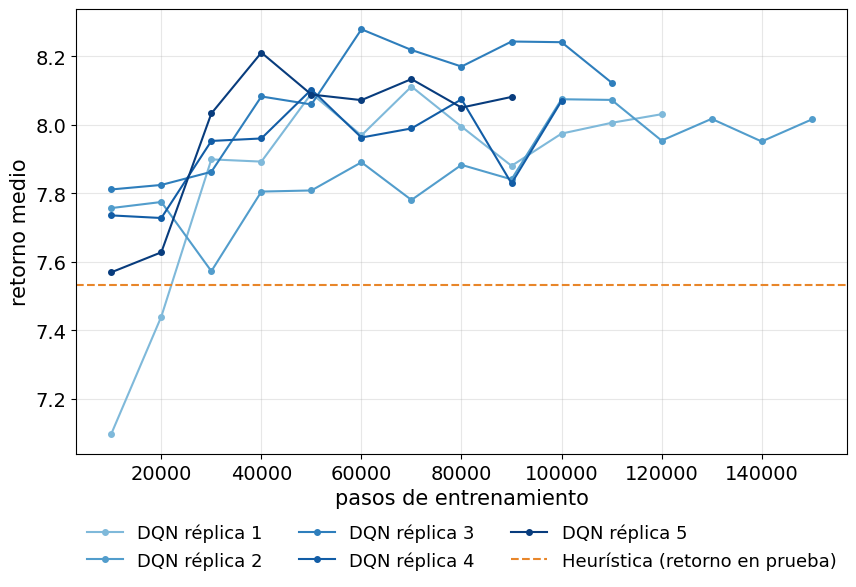

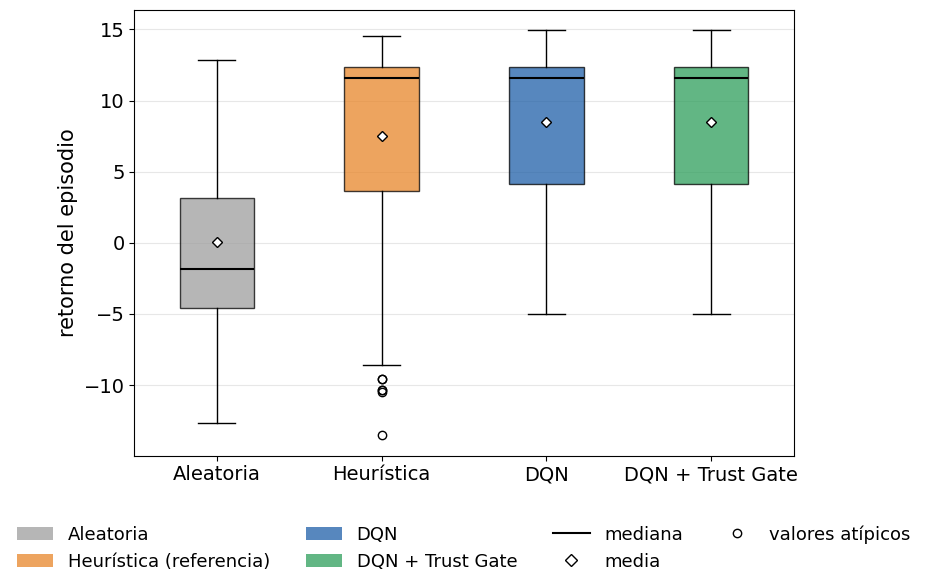

Figuras del artículo guardadas en /content/drive/MyDrive/Proyecto de investigacion/DatosBatsuv2/resultados


In [11]:
# Figuras para el artículo: paneles originales, sin título interno, leyenda completa debajo del gráfico
import matplotlib.pyplot as plt

def figura_articulo(fn, nombre_archivo, columnas=3):
    f, a = plt.subplots(figsize=(9, 6))
    fn(a)
    a.set_title('')                                   # el pie de figura va en LaTeX, no dentro de la imagen
    a.tick_params(labelsize=14)
    a.xaxis.label.set_size(15); a.yaxis.label.set_size(15)
    leg = a.get_legend()
    if leg is not None:
        handles = getattr(leg, 'legend_handles', None) or leg.legendHandles
        labels = [t.get_text() for t in leg.get_texts()]
        a.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=columnas, frameon=False, fontsize=13)
    f.tight_layout()
    f.savefig(RESULTADOS_DIR / nombre_archivo, dpi=200, bbox_inches='tight')
    plt.show(); plt.close(f)

figura_articulo(panel_a, 'fig2_dqn_aprendizaje.png', columnas=3)
figura_articulo(panel_d, 'fig3_dqn_boxplot_episodios.png', columnas=4)
print('Figuras del artículo guardadas en', RESULTADOS_DIR)

## 8. Guardado de resultados

Se guardan la tabla comparativa, el historial de entrenamiento y un registro JSON con los hiperparámetros, el modo de recompensa, el criterio de parada alcanzado y las métricas finales. Junto con el modelo guardado en la Sección 6 y la figura de la Sección 7, es la evidencia de los objetivos específicos 5 y 6.


In [ ]:
import hashlib

def sha_archivo(ruta, n=16):
    return hashlib.sha256(open(ruta, 'rb').read()).hexdigest()[:n]

sufijo = f'{ETIQUETA_CORPUS}_{modo_juez}'
comparacion.to_csv(RESULTADOS_DIR / f'comparacion_{sufijo}.csv')
por_replica.to_csv(RESULTADOS_DIR / f'comparacion_por_replica_{sufijo}.csv', index=False)
hist.to_csv(RESULTADOS_DIR / f'entrenamiento_{sufijo}.csv', index=False)

registro = {
    'etiqueta_corpus': ETIQUETA_CORPUS, 'modo_recompensa': modo_juez, 'fecha': time.strftime('%Y-%m-%d %H:%M:%S'),
    'huellas': {'corpus_parquet': sha_archivo(RUTA_CORPUS), 'batsu_sim.py': sha_archivo(BASE_DIR / 'batsu_sim.py'),
                'prompt_generador': manif.get('generador', {}).get('prompt_sha256'),
                'prompt_juez': manif.get('juez', {}).get('prompt_sha256')},
    'clave_aleatoria': CLAVE_ALEATORIA, 'claves_replicas': CLAVES_REPLICAS,
    'conjuntos': {'seleccion': N_SEL_EPISODIOS, 'prueba': N_TEST_EPISODIOS, 'rng_seleccion': CLAVE_ALEATORIA + 1, 'rng_prueba': CLAVE_ALEATORIA + 2},
    'hiperparametros': {k: (v if not isinstance(v, dict) else str(v)) for k, v in HIPER.items()},
    'criterio_parada': {'max_pasos': MAX_PASOS, 'eval_cada': EVAL_CADA, 'paciencia': PACIENCIA},
    'replicas': {str(r['replica']): {'clave': c, 'pasos': r['pasos'], 'mejor_paso': r['mejor_paso'], 'retorno_seleccion': round(r['mejor_sel'], 3),
                                     'minutos': round(r['minutos'], 1), 'modelo': r['ruta']} for c, r in replicas.items()},
    'versiones': {'sb3': sb3.__version__, 'torch': torch.__version__, 'gymnasium': gym.__version__},
    'comparacion': comparacion.to_dict(orient='index'),
}
if modo_juez == 'modelo':
    registro['modelo_recompensa'] = {'entradas': int(X.shape[1]), 'transiciones_entrenamiento': int(len(Xt)), 'transiciones_validacion': int(len(Xv)),
                                     'episodios_validacion': len(val_eps), 'mse': round(mse, 4), 'mae': round(mae, 3), 'r2': round(r2, 3),
                                     'spearman_orden_acciones': round(float(rho_a), 3), 'spearman_orden_estados': round(float(rho_e), 3)}
json.dump(registro, open(RESULTADOS_DIR / f'registro_{sufijo}.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
print('Guardado en', RESULTADOS_DIR.name, ':', sorted(p.name for p in RESULTADOS_DIR.iterdir() if sufijo in p.name))
print('Huellas:', registro['huellas'])

Guardado en resultados : ['DQN_v0_escala05_prior40_modelo_r1.zip', 'DQN_v0_escala05_prior40_modelo_r2.zip', 'DQN_v0_escala05_prior40_modelo_r3.zip', 'DQN_v0_escala05_prior40_modelo_r4.zip', 'DQN_v0_escala05_prior40_modelo_r5.zip', 'QR-DQN_v0_escala05_prior40_modelo_r1.zip', 'QR-DQN_v0_escala05_prior40_modelo_r2.zip', 'comparacion_por_replica_v0_escala05_prior40_modelo.csv', 'comparacion_v0_escala05_prior40_modelo.csv', 'curvas_v0_escala05_prior40_modelo.png', 'dqn_v0_escala05_prior40_modelo.zip', 'dqn_v0_escala05_prior40_modelo_r1.zip', 'dqn_v0_escala05_prior40_modelo_r2.zip', 'dqn_v0_escala05_prior40_modelo_r3.zip', 'dqn_v0_escala05_prior40_modelo_r4.zip', 'dqn_v0_escala05_prior40_modelo_r5.zip', 'entrenamiento_v0_escala05_prior40_modelo.csv', 'fig_a_aprendizaje_v0_escala05_prior40_modelo.png', 'fig_b_perdida_td_v0_escala05_prior40_modelo.png', 'fig_c_desenlaces_v0_escala05_prior40_modelo.png', 'fig_d_boxplot_retorno_v0_escala05_prior40_modelo.png', 'registro_v0_escala05_prior40_model

In [ ]:
import platform, os
def cpu_modelo():
    try:
        return next(l.split(':', 1)[1].strip() for l in open('/proc/cpuinfo') if l.startswith('model name'))
    except Exception:
        return platform.processor() or 'desconocido'
registro['hardware'] = {'cpu': cpu_modelo(), 'nucleos': os.cpu_count(), 'hilos_torch': torch.get_num_threads()}
json.dump(registro, open(RESULTADOS_DIR / f'registro_{sufijo}.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
print('Hardware:', registro['hardware'])

Hardware: {'cpu': 'AMD EPYC 7B12', 'nucleos': 2, 'hilos_torch': 1}
